# Uçtan Uca Yapay Zeka Projesi: İkinci El Araç Fiyat Tahmini
**Yapay Zeka İçin Basitleştirilmiş Python — Proje Envanteri**
Muhammed Mirhan Serim · Software Persona Yapay Zeka Mesleki Gelişim Programı, 30. Dönem

Bu not defteri, gerçek bir ikinci el araç veri setinden yola çıkarak aracın satış fiyatını tahmin eden bir yapay zeka uygulamasını
uçtan uca geliştirir: **problem tanımı → veri hazırlama → keşif ve görselleştirme → model → değerlendirme → mini uygulama.**

Araçlar: Python, Google Colab, Pandas, NumPy, Matplotlib, scikit-learn

**Sonuç özeti:** Doğrusal regresyonla başlayan model, *değer kaybı oranı* hedefi ve Gradient Boosting ile test verisinde
**R² = 0,785 → 0,968**, ortalama hata **1,38 → 0,61 lakh ₹** seviyesine geliştirildi.

## Aşama 1 · Problem Tanımı ve Proje Planı

| | |
|---|---|
| **Problem cümlesi** | Bir aracın *model yılı, kilometresi, sıfır fiyatı, yakıt tipi, vites türü, satıcı türü ve önceki sahip sayısı* bilgilerinden **ikinci el satış fiyatını** tahmin et. |
| **Hedef değişken (y)** | `Selling_Price`: aracın ikinci el satış fiyatı (lakh ₹, 1 lakh = 100.000 Hint rupisi) |
| **Problem türü** | Çıktı sürekli bir sayı olduğu için **regresyon** |

**Neden önemli?** İkinci el araç alım-satımında fiyat çoğu zaman tahmine ve pazarlığa dayanır. Satıcı aracını
değerinin altında satabilir, alıcı da fazla ödeyebilir. Aracın temel özelliklerinden adil bir fiyat aralığı öneren
basit bir model hem bireysel kullanıcılara hem de galerilere hızlı ve tutarlı bir başlangıç fiyatı sunar.
Ayrıca hangi özelliğin fiyatı ne kadar etkilediğini görmek, kullanıcıların daha bilinçli karar vermesini sağlar.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
RASTGELE = 42  # tekrarlanabilir sonuçlar için sabit tohum

## Aşama 2 · Veri Toplama ve Hazırlama

**Veri kaynağı:** *Vehicle Dataset from CarDekho* (Kaggle, N. Birla). Hindistan'daki CarDekho platformunda listelenmiş
301 ikinci el araç ilanı. Not defteri Colab'da da çalışsın diye veri, dosya yanımızda yoksa GitHub deposundan indirilir.

In [2]:
import os
VERI_URL = "https://raw.githubusercontent.com/mirhanserim/yapay-zeka-portfolyo/main/1_Python_Arac_Fiyat/arac_verisi.csv"
kaynak = "arac_verisi.csv" if os.path.exists("arac_verisi.csv") else VERI_URL
df = pd.read_csv(kaynak)
print("Boyut:", df.shape)
df.head()

Boyut: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


### Veri sözlüğü

| Sütun | Tip | Anlamı | Rol |
|---|---|---|---|
| `Car_Name` | kategorik | Araç model adı | kullanılmadı (98 farklı değer, çok seyrek) |
| `Year` | sayısal | Model yılı | özellik (yaşa çevrilir) |
| `Selling_Price` | sayısal | İkinci el satış fiyatı (lakh ₹) | **hedef (y)** |
| `Present_Price` | sayısal | Aracın sıfır fiyatı (lakh ₹) | özellik |
| `Kms_Driven` | sayısal | Toplam kilometre | özellik |
| `Fuel_Type` | kategorik | Petrol / Diesel / CNG | özellik |
| `Seller_Type` | kategorik | Dealer (galeri) / Individual (bireysel) | özellik |
| `Transmission` | kategorik | Manual / Automatic | özellik |
| `Owner` | sayısal | Önceki sahip sayısı | özellik |

In [3]:
print("Sütun tipleri:\n", df.dtypes, sep="")
print("\nEksik değer sayısı:", int(df.isnull().sum().sum()))
print("Tekrarlanan satır sayısı:", int(df.duplicated().sum()))

Sütun tipleri:
Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type            str
Seller_Type          str
Transmission         str
Owner              int64
dtype: object

Eksik değer sayısı: 0
Tekrarlanan satır sayısı: 2


### Temizleme adımları
1. **Eksik değer:** `isnull()` kontrolünde eksik değer bulunmadı, `fillna`/`dropna` gerekmedi.
2. **Tekrarlanan satırlar:** Aynı ilan iki kez girilmiş 2 satır `drop_duplicates()` ile çıkarıldı.
3. **Aykırı değer:** 500.000 km'lik tek bir kayıt fiziksel olarak mümkün ama dağılımın çok dışında. Modeli tek bir ilan bozmasın diye çıkarıldı.
4. **Özellik türetme:** `Year` yerine daha anlamlı olan **`Arac_Yasi`** (veri setindeki en yeni yıla göre) hesaplandı.
5. **Kategorik → sayısal:** Yakıt, satıcı ve vites sütunları `get_dummies` ile 0/1 sütunlarına çevrildi.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
df = df[df["Kms_Driven"] < 400_000].reset_index(drop=True)
REFERANS_YIL = df["Year"].max() + 1
df["Arac_Yasi"] = REFERANS_YIL - df["Year"]
print("Temizlik sonrası boyut:", df.shape, "| referans yıl:", REFERANS_YIL)

Temizlik sonrası boyut: (298, 10) | referans yıl: 2019


## Aşama 3 · Keşifçi Veri Analizi (EDA) ve Görselleştirme

In [5]:
df[["Selling_Price", "Present_Price", "Kms_Driven", "Arac_Yasi", "Owner"]].describe().round(2)

,Selling_Price,Present_Price,Kms_Driven,Arac_Yasi,Owner
count,298.00,298.00,298.00,298.00,298.00
mean,4.60,7.56,35362.78,5.37,0.04
std,4.99,8.57,28334.52,2.88,0.25
min,0.10,0.32,500.00,1.00,0.00
25%,0.90,1.21,15000.00,3.00,0.00
50%,3.56,6.25,31802.00,5.00,0.00
75%,6.00,9.84,48575.25,7.00,0.00
max,35.00,92.60,213000.00,16.00,3.00


In [6]:
print("Kategorik sütunların dağılımı (value_counts):")
for sutun in ["Fuel_Type", "Seller_Type", "Transmission", "Owner"]:
    print(f"\n{sutun}:", df[sutun].value_counts().to_dict())

Kategorik sütunların dağılımı (value_counts):

Fuel_Type: {'Petrol': 238, 'Diesel': 58, 'CNG': 2}

Seller_Type: {'Dealer': 193, 'Individual': 105}

Transmission: {'Manual': 260, 'Automatic': 38}

Owner: {0: 287, 1: 10, 3: 1}


In [7]:
print("Yakıt tipine göre ortalama satış fiyatı (lakh ₹):")
print(df.groupby("Fuel_Type")["Selling_Price"].agg(["count", "mean"]).round(2))
print("\nVites türüne göre:")
print(df.groupby("Transmission")["Selling_Price"].agg(["count", "mean"]).round(2))
print("\nSatıcı türüne göre:")
print(df.groupby("Seller_Type")["Selling_Price"].agg(["count", "mean"]).round(2))

Yakıt tipine göre ortalama satış fiyatı (lakh ₹):
           count   mean
Fuel_Type              
CNG            2   3.10
Diesel        58  10.10
Petrol       238   3.28

Vites türüne göre:
              count  mean
Transmission             
Automatic        38  9.31
Manual          260  3.92

Satıcı türüne göre:
             count  mean
Seller_Type             
Dealer         193  6.63
Individual     105  0.88


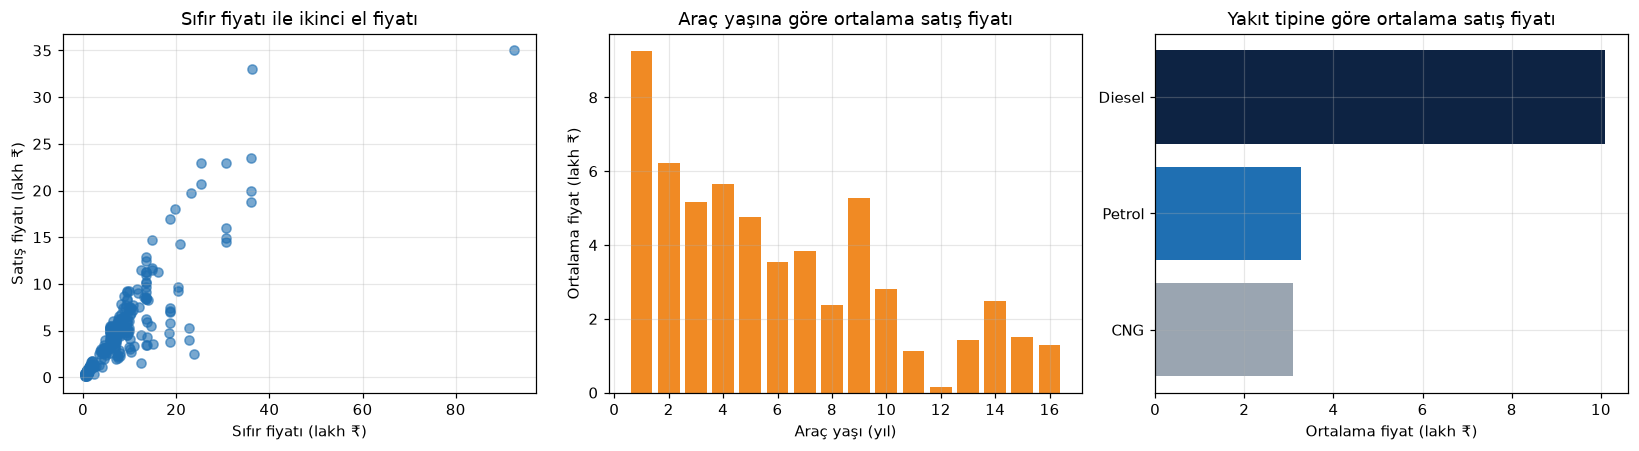

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].scatter(df["Present_Price"], df["Selling_Price"], alpha=0.6, c="#1f6fb2")
ax[0].set_title("Sıfır fiyatı ile ikinci el fiyatı")
ax[0].set_xlabel("Sıfır fiyatı (lakh ₹)"); ax[0].set_ylabel("Satış fiyatı (lakh ₹)")

ort = df.groupby("Arac_Yasi")["Selling_Price"].mean()
ax[1].bar(ort.index, ort.values, color="#f08a24")
ax[1].set_title("Araç yaşına göre ortalama satış fiyatı")
ax[1].set_xlabel("Araç yaşı (yıl)"); ax[1].set_ylabel("Ortalama fiyat (lakh ₹)")

yakit = df.groupby("Fuel_Type")["Selling_Price"].mean().sort_values()
ax[2].barh(yakit.index, yakit.values, color=["#9aa5b1", "#1f6fb2", "#0d2343"])
ax[2].set_title("Yakıt tipine göre ortalama satış fiyatı")
ax[2].set_xlabel("Ortalama fiyat (lakh ₹)")
plt.tight_layout(); plt.savefig("grafik_eda.png", dpi=160, bbox_inches="tight"); plt.show()

In [9]:
korelasyon = df[["Selling_Price", "Present_Price", "Kms_Driven", "Arac_Yasi", "Owner"]].corr()["Selling_Price"].drop("Selling_Price")
print("Satış fiyatı ile korelasyon:\n", korelasyon.sort_values(ascending=False).round(2), sep="")

Satış fiyatı ile korelasyon:
Present_Price    0.88
Kms_Driven       0.09
Owner           -0.09
Arac_Yasi       -0.23
Name: Selling_Price, dtype: float64


### Keşif Bulguları
1. **Sıfır fiyatı en belirleyici özellik:** `Present_Price` ile satış fiyatı arasında çok güçlü doğrusal bir ilişki var (korelasyon ≈ 0,88).
2. **Araç yaşlandıkça fiyat düşüyor:** Yaşın fiyatla korelasyonu negatif (≈ −0,23). Tek başına zayıf görünse de sıfır fiyatı sabit tutulduğunda etkisi netleşiyor (modelde her yıl ≈ 0,28 lakh ₹ düşüş).
3. **Dizel araçlar daha pahalı:** Dizel araçların ortalama fiyatı benzinlilerin yaklaşık 3 katı. Bu fark büyük ölçüde dizellerin daha üst segment olmasından kaynaklanıyor.
4. **Otomatik vites ve galeri satışı fiyatı artırıyor:** Bireysel satıcıların araçları çoğunlukla düşük fiyatlı küçük araçlar ve motosikletler.
5. **Kilometrenin etkisi tek başına zayıf:** Km'nin fiyatla korelasyonu yalnızca ≈ 0,09. Km büyük ölçüde yaşla birlikte değiştiği için ayrı bir bilgi taşımıyor.

## Aşama 4 · Model Kurma ve Eğitme

In [10]:
OZELLIKLER = ["Present_Price", "Kms_Driven", "Arac_Yasi", "Owner", "Fuel_Type", "Seller_Type", "Transmission"]
X = pd.get_dummies(df[OZELLIKLER], columns=["Fuel_Type", "Seller_Type", "Transmission"], drop_first=True, dtype=int)
y = df["Selling_Price"]

X_egitim, X_test, y_egitim, y_test = train_test_split(X, y, test_size=0.2, random_state=RASTGELE)
print("Eğitim:", X_egitim.shape, "| Test:", X_test.shape, "→ %80 eğitim / %20 test")
print("Kullanılan sütunlar:", list(X.columns))

Eğitim: (238, 8) | Test: (60, 8) → %80 eğitim / %20 test
Kullanılan sütunlar: ['Present_Price', 'Kms_Driven', 'Arac_Yasi', 'Owner', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Seller_Type_Individual', 'Transmission_Manual']


### 4.1 Temel model: Doğrusal Regresyon
Keşif aşamasında satış fiyatının sıfır fiyatıyla doğrusal bir ilişki gösterdiği görüldü. Bu yüzden ilk (temel) model olarak
hem yorumlanabilir hem de hızlı olan **Doğrusal Regresyon** kuruldu. Katsayıları her özelliğin fiyata etkisini doğrudan gösterir.

In [11]:
model_lr = LinearRegression()
model_lr.fit(X_egitim, y_egitim)
katsayilar = pd.Series(model_lr.coef_, index=X.columns).round(3)
print("Doğrusal regresyon katsayıları:\n", katsayilar, sep="")

Doğrusal regresyon katsayıları:
Present_Price             0.440
Kms_Driven               -0.000
Arac_Yasi                -0.282
Owner                     0.477
Fuel_Type_Diesel          2.274
Fuel_Type_Petrol          0.669
Seller_Type_Individual   -1.352
Transmission_Manual      -1.558
dtype: float64


### 4.2 Farklı modelleri denemek
Tek bir modelle yetinmemek için doğrusal olmayan ilişkileri yakalayabilen ağaç tabanlı modeller de denendi:
**Karar Ağacı**, **Random Forest** (yüzlerce ağacın ortalaması) ve **Gradient Boosting** (her ağacın bir öncekinin hatasını düzelttiği
boosting yöntemi). Tek bir test bölmesi şansa bağlı olabileceği için her model ayrıca **5 katlı çapraz doğrulama** ile ölçüldü.

In [12]:
def capraz_r2(yap, oran_hedefi=False, k=5):
    """5 katlı çapraz doğrulamada ortalama R² (oran hedefinde tahmin tekrar fiyata çevrilir)."""
    skorlar = []
    for egt, tst in KFold(k, shuffle=True, random_state=RASTGELE).split(X):
        m = yap()
        hedef = y.iloc[egt] / X.iloc[egt]["Present_Price"] if oran_hedefi else y.iloc[egt]
        m.fit(X.iloc[egt], hedef)
        p = m.predict(X.iloc[tst]) * (X.iloc[tst]["Present_Price"] if oran_hedefi else 1)
        skorlar.append(r2_score(y.iloc[tst], p))
    return np.mean(skorlar), np.std(skorlar)

ADAYLAR = {
    "Doğrusal Regresyon": lambda: LinearRegression(),
    "Karar Ağacı (derinlik 5)": lambda: DecisionTreeRegressor(max_depth=5, random_state=RASTGELE),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RASTGELE),
    "Gradient Boosting": lambda: GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RASTGELE),
}

def olc(ad, yap, oran_hedefi=False):
    m = yap()
    m.fit(X_egitim, y_egitim / X_egitim["Present_Price"] if oran_hedefi else y_egitim)
    carpan_e = X_egitim["Present_Price"] if oran_hedefi else 1
    carpan_t = X_test["Present_Price"] if oran_hedefi else 1
    p_e, p_t = m.predict(X_egitim) * carpan_e, m.predict(X_test) * carpan_t
    cv_ort, cv_std = capraz_r2(yap, oran_hedefi)
    return m, {"Model": ad, "Hedef": "Değer kaybı oranı" if oran_hedefi else "Fiyat",
               "Eğitim R²": round(r2_score(y_egitim, p_e), 3), "Test R²": round(r2_score(y_test, p_t), 3),
               "Test MAE (lakh ₹)": round(mean_absolute_error(y_test, p_t), 2), "5-kat CV R²": f"{cv_ort:.3f} ± {cv_std:.3f}"}

sonuclar = [olc(ad, yap)[1] for ad, yap in ADAYLAR.items()]
pd.DataFrame(sonuclar)

,Model,Hedef,Eğitim R²,Test R²,Test MAE (lakh ₹),5-kat CV R²
0,Doğrusal Regresyon,Fiyat,0.906,0.785,1.38,0.858 ± 0.046
1,Karar Ağacı (derinlik 5),Fiyat,0.976,0.805,1.29,0.896 ± 0.050
2,Random Forest,Fiyat,0.956,0.606,1.43,0.851 ± 0.130
3,Gradient Boosting,Fiyat,0.998,0.742,1.17,0.900 ± 0.092


**Beklenmedik bulgu:** Random Forest ve Gradient Boosting eğitim verisinde neredeyse kusursuz, ama test verisinde doğrusal modelden
**kötü**. Sebep, ağaç modellerinin bir sınırlılığı: **gördükleri en yüksek değerin üzerine tahmin yapamazlar (dışa genelleme yok).**
Test setindeki birkaç pahalı araç, eğitimdeki fiyat aralığının dışında kaldığı için ağaçlar bu araçları düşük tahmin ediyor.

### 4.3 Çözüm: fiyatı değil, *değer kaybı oranını* tahmin etmek
Bir aracın ikinci el fiyatını belirleyen asıl şey, sıfır fiyatına göre **ne kadar değer kaybettiğidir**.
Bu yüzden hedef değişken `Selling_Price` yerine **`oran = Selling_Price / Present_Price`** olarak yeniden tanımlandı.
Oran tüm araçlar için 0 ile 1 arasında ve fiyat ölçeğinden bağımsız. Model oranı öğreniyor, tahmin `oran × sıfır fiyatı` ile tekrar fiyata çevriliyor.

In [13]:
sonuclar_oran = []
modeller_oran = {}
for ad in ["Doğrusal Regresyon", "Random Forest", "Gradient Boosting"]:
    m, satir = olc(ad, ADAYLAR[ad], oran_hedefi=True)
    modeller_oran[ad] = m; sonuclar_oran.append(satir)

karsilastirma = pd.DataFrame(sonuclar + sonuclar_oran)
karsilastirma

,Model,Hedef,Eğitim R²,Test R²,Test MAE (lakh ₹),5-kat CV R²
0,Doğrusal Regresyon,Fiyat,0.906,0.785,1.38,0.858 ± 0.046
1,Karar Ağacı (derinlik 5),Fiyat,0.976,0.805,1.29,0.896 ± 0.050
2,Random Forest,Fiyat,0.956,0.606,1.43,0.851 ± 0.130
3,Gradient Boosting,Fiyat,0.998,0.742,1.17,0.900 ± 0.092
4,Doğrusal Regresyon,Değer kaybı oranı,0.942,0.918,0.80,0.812 ± 0.275
5,Random Forest,Değer kaybı oranı,0.993,0.959,0.66,0.968 ± 0.009
6,Gradient Boosting,Değer kaybı oranı,0.996,0.968,0.61,0.976 ± 0.007


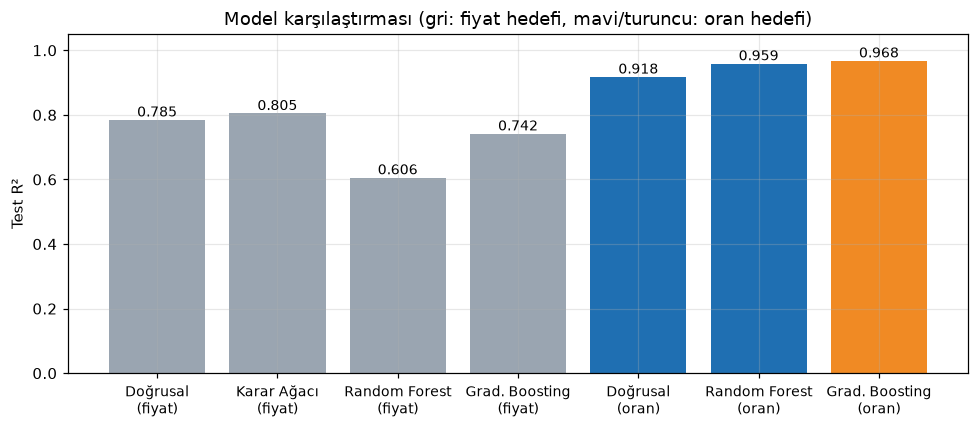

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
KISA = {"Doğrusal Regresyon": "Doğrusal", "Karar Ağacı (derinlik 5)": "Karar Ağacı", "Random Forest": "Random Forest", "Gradient Boosting": "Grad. Boosting"}
etiket = karsilastirma["Model"].map(KISA) + "\n(" + karsilastirma["Hedef"].str.replace("Değer kaybı oranı", "oran").str.lower() + ")"
renk = ["#9aa5b1" if h == "Fiyat" else "#1f6fb2" for h in karsilastirma["Hedef"]]
renk[-1] = "#f08a24"
ax.bar(etiket, karsilastirma["Test R²"], color=renk)
for i, v in enumerate(karsilastirma["Test R²"]): ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylim(0, 1.05); ax.set_ylabel("Test R²"); ax.set_title("Model karşılaştırması (gri: fiyat hedefi, mavi/turuncu: oran hedefi)")
plt.xticks(fontsize=9); plt.tight_layout(); plt.savefig("grafik_modeller.png", dpi=160, bbox_inches="tight"); plt.show()

**Model seçimi:** Oran hedefiyle eğitilen **Gradient Boosting**, test verisinde en yüksek doğruluğu (R² = 0,968) ve en düşük hatayı
(0,61 lakh ₹) verdi. Daha önemlisi, 5 katlı çapraz doğrulamada da **0,976 ± 0,007** ile hem en başarılı hem de **en kararlı** model.
Bu yüzden son model olarak seçildi. Doğrusal regresyon, yorumlanabilir **temel model** olarak karşılaştırmada tutuldu.

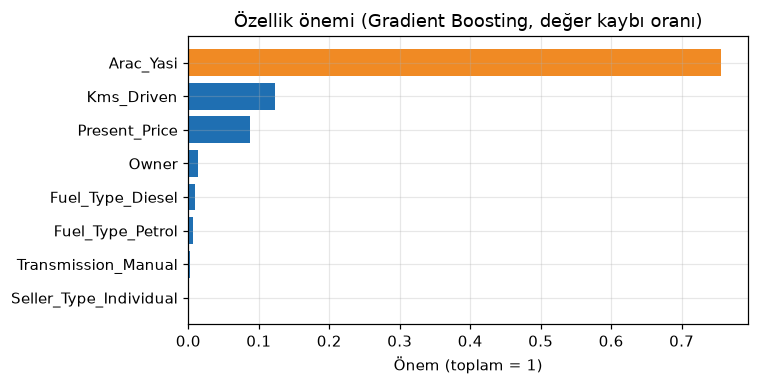

Arac_Yasi                 0.756
Kms_Driven                0.123
Present_Price             0.087
Owner                     0.014
Fuel_Type_Diesel          0.009
Fuel_Type_Petrol          0.006
Transmission_Manual       0.003
Seller_Type_Individual    0.001
dtype: float64


In [15]:
model = modeller_oran["Gradient Boosting"]   # son model

def fiyat_tahmini(tablo):
    """Model değer kaybı oranını tahmin eder, sıfır fiyatıyla çarpılarak fiyata çevrilir."""
    return model.predict(tablo) * tablo["Present_Price"].to_numpy()

onem = pd.Series(model.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(onem.index, onem.values, color=["#f08a24" if v == onem.max() else "#1f6fb2" for v in onem.values])
ax.set_title("Özellik önemi (Gradient Boosting, değer kaybı oranı)"); ax.set_xlabel("Önem (toplam = 1)")
plt.tight_layout(); plt.savefig("grafik_onem.png", dpi=160, bbox_inches="tight"); plt.show()
print(onem.sort_values(ascending=False).round(3))

**Özellik önemi yorumu:** Değer kaybını en çok **araç yaşı** (≈ %76) ve **kilometre** (≈ %12) belirliyor. Bu, gerçek hayattaki
sezgiyle örtüşüyor: aynı model bir araç yaşlandıkça ve yol yaptıkça değer kaybeder. Fiyat hedefinde baskın görünen sıfır fiyatı,
oran hedefinde yalnızca ≈ %9 önem taşıyor. Çünkü ölçek etkisi artık hedefin içinde.

## Aşama 5 · Tahmin ve Değerlendirme

Son model · Test R² = 0.968 | Test MAE = 0.61 lakh ₹


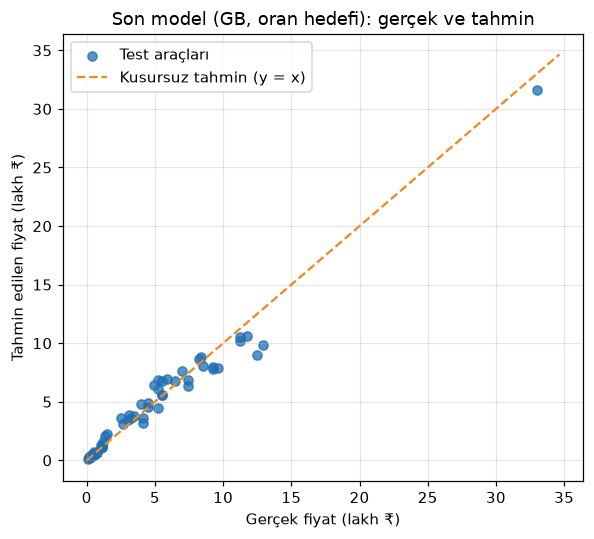

In [16]:
tahmin = fiyat_tahmini(X_test)
print(f"Son model · Test R² = {r2_score(y_test, tahmin):.3f} | Test MAE = {mean_absolute_error(y_test, tahmin):.2f} lakh ₹")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_test, tahmin, alpha=0.75, c="#1f6fb2", label="Test araçları")
sinir = [0, max(y_test.max(), tahmin.max()) * 1.05]
ax.plot(sinir, sinir, "--", c="#f08a24", label="Kusursuz tahmin (y = x)")
ax.set_xlabel("Gerçek fiyat (lakh ₹)"); ax.set_ylabel("Tahmin edilen fiyat (lakh ₹)")
ax.set_title("Son model (GB, oran hedefi): gerçek ve tahmin"); ax.legend()
plt.tight_layout(); plt.savefig("grafik_tahmin.png", dpi=160, bbox_inches="tight"); plt.show()

### Modele nerede güvenebilirim?
Ortalama hata tek başına yanıltıcı olabilir. Bu yüzden hata, araç fiyat segmentlerine göre ayrı ayrı incelendi.

In [17]:
segment = pd.cut(y_test, [0, 2, 5, 10, 100], labels=["< 2 lakh", "2–5 lakh", "5–10 lakh", "> 10 lakh"])
hata_tablosu = (pd.DataFrame({"segment": segment, "mutlak_hata": (y_test - tahmin).abs(), "yuzde_hata": ((y_test - tahmin).abs() / y_test * 100)})
                .groupby("segment", observed=True).agg(arac=("mutlak_hata", "size"), ort_hata_lakh=("mutlak_hata", "mean"), ort_hata_yuzde=("yuzde_hata", "mean")).round(2))
hata_tablosu

,arac,ort_hata_lakh,ort_hata_yuzde
segment,,,
< 2 lakh,25,0.14,20.54
2–5 lakh,12,0.64,18.18
5–10 lakh,17,0.84,12.26
> 10 lakh,6,1.81,13.58


In [18]:
yeni_araclar = pd.DataFrame([
    {"Present_Price": 6.0,  "Kms_Driven": 20_000, "Arac_Yasi": 2, "Owner": 0, "Fuel_Type": "Petrol", "Seller_Type": "Dealer",     "Transmission": "Manual"},
    {"Present_Price": 12.0, "Kms_Driven": 60_000, "Arac_Yasi": 6, "Owner": 0, "Fuel_Type": "Diesel", "Seller_Type": "Dealer",     "Transmission": "Manual"},
    {"Present_Price": 20.0, "Kms_Driven": 35_000, "Arac_Yasi": 3, "Owner": 1, "Fuel_Type": "Diesel", "Seller_Type": "Dealer",     "Transmission": "Automatic"},
    {"Present_Price": 0.8,  "Kms_Driven": 15_000, "Arac_Yasi": 4, "Owner": 0, "Fuel_Type": "Petrol", "Seller_Type": "Individual", "Transmission": "Manual"},
])

def hazirla(tablo):
    """Yeni girdileri modelin beklediği sütun yapısına çevirir."""
    return pd.get_dummies(tablo, columns=["Fuel_Type", "Seller_Type", "Transmission"], dtype=int).reindex(columns=X.columns, fill_value=0)

yeni_araclar["Tahmin (lakh ₹)"] = fiyat_tahmini(hazirla(yeni_araclar)).round(2)
yeni_araclar

,Present_Price,Kms_Driven,Arac_Yasi,Owner,Fuel_Type,Seller_Type,Transmission,Tahmin (lakh ₹)
0,6.0,20000,2,0,Petrol,Dealer,Manual,5.34
1,12.0,60000,6,0,Diesel,Dealer,Manual,6.73
2,20.0,35000,3,1,Diesel,Dealer,Automatic,16.12
3,0.8,15000,4,0,Petrol,Individual,Manual,0.57


### Değerlendirme Notu
- **Başarı:** Son model test verisinde **R² = 0,968** ve **ortalama mutlak hata = 0,61 lakh ₹** elde etti. Temel doğrusal modele göre
  (R² = 0,785, MAE = 1,38) hata yarıdan fazla azaldı. 5 katlı çapraz doğrulamada R² = 0,976 ± 0,007: sonuç tek bir şanslı bölmeye bağlı değil.
- **Aşırı öğrenme kontrolü:** Eğitim (≈ 0,996) ile test/çapraz doğrulama skoru arasındaki fark küçük ve skor katlar arasında çok az değişiyor.
  Fiyat hedefli ağaç modellerinde görülen büyük düşüş (Random Forest: 0,956 → 0,606) oran hedefiyle ortadan kalktı.
- **Nerede güvenilir?** Orta ve üst segmentte (5 lakh ₹ üzeri) yüzde hata en düşük (≈ %12–14). 2 lakh ₹ altındaki çok ucuz araçlarda
  (çoğu motosiklet) mutlak hata yalnızca ≈ 0,14 lakh ₹ olsa da fiyat küçük olduğu için yüzde hata ≈ %20'ye çıkıyor.
  10 lakh ₹ üzerindeki pahalı araçlarda örnek az (6 araç) ve mutlak hata ≈ 1,8 lakh ₹. Bu segmentte tahmin bir başlangıç noktası olarak kullanılmalı.
- **Zayıf yönler:** Veri küçük (298 ilan) ve tek bir ülkeye (Hindistan) ait. Marka, hasar ve bakım geçmişi gibi önemli bilgiler yok.
  `Owner` gibi az örnekli özelliklerden güvenilir bir etki öğrenilemiyor.
- **İyileştirme önerileri:** Marka/model bilgisi eklemek, daha büyük ve güncel veriyle çalışmak, hiperparametreleri çapraz doğrulamayla ayarlamak.

## Aşama 6 · Akıllı Tahmin Aracı (Mini Uygulama)

In [19]:
def tahmin_et(sifir_fiyati, km, yas, sahip_sayisi=0, yakit="Petrol", satici="Dealer", vites="Manual"):
    """Araç bilgilerini alır, tahmini satış fiyatını okunur bir cümleyle döndürür."""
    girdi = pd.DataFrame([{"Present_Price": sifir_fiyati, "Kms_Driven": km, "Arac_Yasi": yas, "Owner": sahip_sayisi,
                           "Fuel_Type": yakit, "Seller_Type": satici, "Transmission": vites}])
    fiyat = max(float(fiyat_tahmini(hazirla(girdi))[0]), 0.0)
    hata = mean_absolute_error(y_test, fiyat_tahmini(X_test))   # test verisindeki ortalama hata
    alt, ust = max(fiyat - hata, 0.0), fiyat + hata
    km_yazi = f"{km:,}".replace(",", ".")
    return (f"{yas} yaşında, {km_yazi} km'deki {yakit.lower()} / {vites.lower()} aracınız için tahmini satış fiyatı "
            f"{fiyat:.2f} lakh ₹ (yaklaşık {alt:.2f} – {ust:.2f} lakh ₹ aralığında).")

def kullanicidan_al():
    """Colab'da kullanıcıdan girdi alır. Etkileşimsiz ortamda örnek değerlerle çalışır."""
    try:
        sifir = float(input("Aracın sıfır fiyatı (lakh ₹): "))
        km = int(input("Kilometre: "))
        yas = int(input("Araç yaşı (yıl): "))
        yakit = input("Yakıt (Petrol/Diesel/CNG): ").strip().capitalize() or "Petrol"
        vites = input("Vites (Manual/Automatic): ").strip().capitalize() or "Manual"
    except Exception:
        print("(Etkileşimsiz çalıştırma: örnek değerler kullanıldı)")
        sifir, km, yas, yakit, vites = 9.5, 40_000, 5, "Diesel", "Manual"
    print(tahmin_et(sifir, km, yas, yakit=yakit, vites=vites))

kullanicidan_al()

(Etkileşimsiz çalıştırma: örnek değerler kullanıldı)
5 yaşında, 40.000 km'deki diesel / manual aracınız için tahmini satış fiyatı 5.59 lakh ₹ (yaklaşık 4.99 – 6.20 lakh ₹ aralığında).


In [20]:
# Örnek çalıştırmalar
print(tahmin_et(5.5, 25_000, 3))
print(tahmin_et(15.0, 50_000, 4, yakit="Diesel", vites="Automatic"))

3 yaşında, 25.000 km'deki petrol / manual aracınız için tahmini satış fiyatı 4.38 lakh ₹ (yaklaşık 3.77 – 4.98 lakh ₹ aralığında).
4 yaşında, 50.000 km'deki diesel / automatic aracınız için tahmini satış fiyatı 10.87 lakh ₹ (yaklaşık 10.26 – 11.47 lakh ₹ aralığında).


## Aşama 7 · Dokümantasyon ve Sonuç

- **Problem:** İkinci el aracın özelliklerinden satış fiyatını tahmin etmek (regresyon, dar yapay zeka).
- **Veri:** CarDekho veri seti, temizlik sonrası 298 ilan, 7 özellik.
- **Yöntem:** Kategorik değişkenlerin kodlanması, %80/%20 eğitim-test bölmesi + 5 katlı çapraz doğrulama, 4 farklı model,
  hedefin *değer kaybı oranı* olarak yeniden tanımlanması, son model Gradient Boosting.
- **Sonuç:** Test verisinde R² = 0,968 ve ortalama 0,61 lakh ₹ hata. Değer kaybını en çok araç yaşı ve kilometre belirliyor.

### Ne öğrendim?
1. **Problemi doğru tanımlamak, modeli değiştirmekten daha etkili olabilir.** En büyük kazanç daha karmaşık bir modelden değil,
   hedefin "fiyat" yerine "değer kaybı oranı" olarak yeniden tanımlanmasından geldi.
2. **Eğitim skoru yanıltabilir.** Random Forest eğitimde 0,96, testte 0,61 aldı. Her zaman ayrı test verisi ve çapraz doğrulama gerekiyor.
3. **Her modelin bir sınırı var.** Ağaç modelleri gördükleri aralığın dışına tahmin yapamıyor. Bunu bilmek, doğru çözümü bulmayı sağladı.
4. **Basit model iyi bir başlangıçtır.** Doğrusal regresyon hem kıyas noktası oldu hem de ilk içgörüleri verdi.

Proje kapsamında hazırlanan **sunum** (5 slayt) ve **1 sayfalık rapor** bu not defterinin sonuçlarına dayanır.